## CAT Assignment 1

Name: Balakumaran S<br>
Reg. No.: 3122247001010






## Setup & configuration

In [45]:
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
SEED = 42
np.random.seed(SEED)

MOBILE_CSV      = "Mobile-Price-Prediction.csv"
MOBILE_TARGET   = None
BANKNOTE_FILE   = "data_banknote_authentication.txt"
TEST_SIZE       = 0.2

# Part 1 – Regression: Mobile Phone Price Prediction

## 1.0 Data loading and preprocessing


In [46]:
def make_synthetic_mobile(n=800, seed=0):
    # Stand-in data used ONLY if the real csv is missing, so the notebook stays runnable.
    rng = np.random.default_rng(seed)
    brand = rng.choice(["Apple", "Samsung", "Xiaomi", "OnePlus", "Oppo", "Realme"], n)
    ram = rng.choice([3, 4, 6, 8, 12, 16], n)
    storage = rng.choice([32, 64, 128, 256, 512], n)
    screen = rng.uniform(5.0, 7.2, n).round(1)
    cam = rng.choice([8, 12, 16, 48, 50, 64, 108], n)
    batt = rng.integers(3000, 6000, n)
    brand_eff = {"Apple": 25000, "Samsung": 8000, "Xiaomi": 0, "OnePlus": 6000, "Oppo": 1500, "Realme": -1500}
    price = (2000 * ram + 60 * storage + 3000 * screen + 120 * cam + 2 * batt
             + np.array([brand_eff[b] for b in brand]) + rng.normal(0, 3000, n))
    return pd.DataFrame({"Brand": brand, "RAM": ram, "Storage": storage, "Screen_Size": screen,
                         "Camera_MP": cam, "Battery": batt, "Price": price.round(0)})

USING_SYNTHETIC_MOBILE = not os.path.exists(MOBILE_CSV)
if USING_SYNTHETIC_MOBILE:
    print(f"WARNING: '{MOBILE_CSV}' not found -> using SYNTHETIC stand-in data.")
    raw = make_synthetic_mobile()
else:
    raw = pd.read_csv(MOBILE_CSV)

if MOBILE_TARGET is None:
    cands = [c for c in raw.columns if "price" in c.lower()]
    assert cands, "Set MOBILE_TARGET to the name of the price column."
    MOBILE_TARGET = cands[0]
print("Target column:", MOBILE_TARGET, "| raw shape:", raw.shape)

def to_numeric_clean(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")

df = raw.copy()
df[MOBILE_TARGET] = to_numeric_clean(df[MOBILE_TARGET])
df = df.dropna(subset=[MOBILE_TARGET]).drop_duplicates()

for c in df.columns.drop(MOBILE_TARGET):                      # "128 GB", "6.5 inches" -> numbers
    if not pd.api.types.is_numeric_dtype(df[c]):
        conv = to_numeric_clean(df[c])
        if conv.notna().mean() > 0.9:
            df[c] = conv

for c in df.columns.drop(MOBILE_TARGET):                      # drop ID-like / very high-cardinality text columns
    if (not pd.api.types.is_numeric_dtype(df[c])) and (df[c].nunique() > 50 or df[c].nunique() / len(df) > 0.5):
        print("Dropping high-cardinality column:", c)
        df = df.drop(columns=c)

for c in df.columns.drop(MOBILE_TARGET):                      # impute
    df[c] = df[c].fillna(df[c].median() if pd.api.types.is_numeric_dtype(df[c]) else df[c].mode()[0])

X_df = pd.get_dummies(df.drop(columns=[MOBILE_TARGET]), drop_first=True).astype(float)
X_df = X_df.loc[:, X_df.std() > 0]                            # drop constant columns
feat_names = list(X_df.columns)
X_all = X_df.values
y_all = df[MOBILE_TARGET].values.reshape(-1, 1)
print("Design matrix (before bias):", X_all.shape, "| features:", len(feat_names))
display(df.head())

Target column: Price | raw shape: (807, 8)
Design matrix (before bias): (548, 7) | features: 7


,Ratings,RAM,ROM,Mobile_Size,Primary_Cam,Selfi_Cam,Battery_Power,Price
0,4.3,4.0,128.0,6.00,48.0,13.0,4000,24999
1,3.4,6.0,64.0,4.50,48.0,12.0,4000,15999
2,4.3,4.0,4.0,4.50,64.0,16.0,4000,15000
3,4.4,6.0,64.0,6.40,48.0,15.0,3800,18999
4,4.5,6.0,128.0,6.18,35.0,15.0,3800,18999


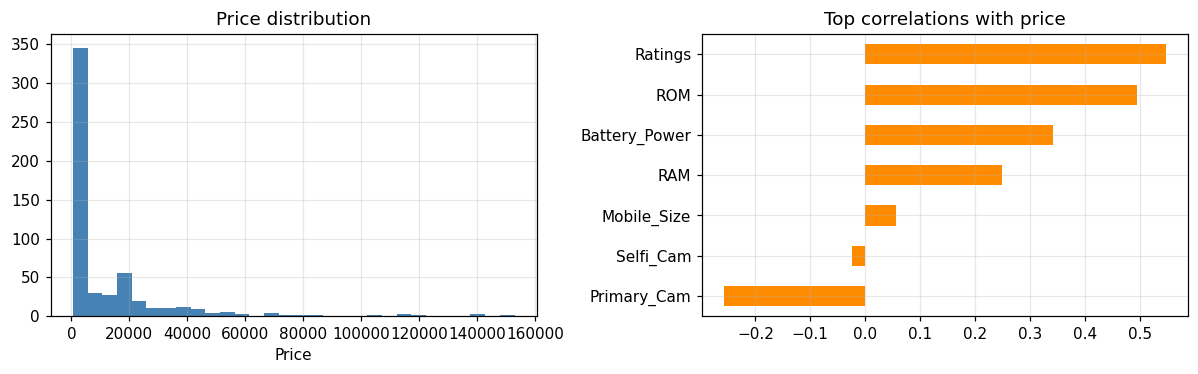

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(y_all, bins=30, color="steelblue"); ax[0].set_title("Price distribution"); ax[0].set_xlabel("Price")
corr = pd.concat([X_df, df[MOBILE_TARGET]], axis=1).corr()[MOBILE_TARGET].drop(MOBILE_TARGET).sort_values()
corr.tail(12).plot.barh(ax=ax[1], color="darkorange"); ax[1].set_title("Top correlations with price")
plt.tight_layout(); plt.show()

## 1.1 Train/test split and its effect on learning


In [48]:
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=TEST_SIZE, random_state=SEED)
print("Train:", Xtr.shape, ytr.shape, "| Test:", Xte.shape, yte.shape)

# ---------- helpers (pure NumPy: matrix formulation) ----------
def add_bias(X):                      # prepend a column of ones -> intercept theta_0
    return np.hstack([np.ones((X.shape[0], 1)), X])

def rmse(y, yh): return float(np.sqrt(np.mean((y - yh) ** 2)))
def mae(y, yh):  return float(np.mean(np.abs(y - yh)))
def r2(y, yh):   return float(1 - np.sum((y - yh) ** 2) / np.sum((y - y.mean()) ** 2))
def mape(y, yh): return float(np.mean(np.abs((y - yh) / np.where(y == 0, np.nan, y))) * 100)
def all_metrics(y, yh):
    return {"MSE": float(np.mean((y - yh) ** 2)), "RMSE": rmse(y, yh), "MAE": mae(y, yh), "R2": r2(y, yh), "MAPE%": mape(y, yh)}

def closed_form(Xb, y, lam=0.0):
    # theta = (X^T X + lam*I')^{-1} X^T y   (I' = identity with the bias entry zeroed -> bias not penalised)
    R = np.eye(Xb.shape[1]); R[0, 0] = 0.0
    return np.linalg.pinv(Xb.T @ Xb + lam * R) @ Xb.T @ y

def gradient_descent(Xb, y, lam=0.0, lr=None, n_iter=20000, tol=1e-12):
    # J(theta) = 1/(2n) * ( ||X theta - y||^2 + lam*||w||^2 ),   grad = 1/n * ( X^T(X theta - y) + lam*R theta )
    n, d = Xb.shape
    R = np.ones((d, 1)); R[0] = 0.0
    if lr is None:                    # safe step 1/L, L = largest eigenvalue of the Hessian
        lr = 1.0 / np.linalg.eigvalsh((Xb.T @ Xb + lam * np.diag(R.ravel())) / n).max()
    theta = np.zeros((d, 1)); hist = []
    for i in range(n_iter):
        err = Xb @ theta - y
        hist.append(float((err.T @ err).item() + lam * np.sum((R * theta) ** 2)) / (2 * n))
        theta = theta - lr * (Xb.T @ err + lam * R * theta) / n
        if i > 0 and abs(hist[-2] - hist[-1]) < tol * max(1.0, hist[-2]):
            break
    return theta, hist, lr

def scatter_pred(ax, y, yh, title):
    ax.scatter(y, yh, s=12, alpha=0.6)
    lo, hi = min(y.min(), yh.min()), max(y.max(), yh.max())
    ax.plot([lo, hi], [lo, hi], "r--", label="ideal y = ŷ")
    ax.set_xlabel("Actual price"); ax.set_ylabel("Predicted price")
    ax.set_title(f"{title}\nR²={r2(y, yh):.3f}  RMSE={rmse(y, yh):,.0f}"); ax.legend()

Train: (438, 7) (438, 1) | Test: (110, 7) (110, 1)


,test_frac,train_frac,train_RMSE,test_RMSE_mean,test_RMSE_std,test_R2_mean
0,0.1,0.9,16056.204,14738.465,3964.454,0.375
1,0.2,0.8,15806.845,16408.182,3010.515,0.431
2,0.3,0.7,15953.926,15959.811,2062.301,0.438
3,0.4,0.6,15696.629,16482.683,1571.991,0.432
4,0.5,0.5,15517.269,16529.989,1267.129,0.426
5,0.6,0.4,15339.338,18726.723,6655.146,0.161


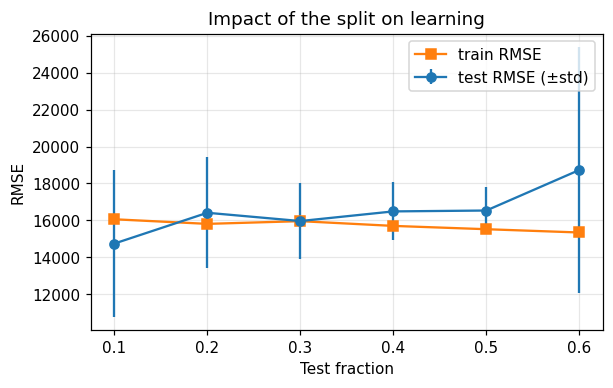

In [49]:
# ---- Effect of the train/test ratio (10 random repeats each) ----
rows = []
for ts in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    tr_e, te_e, te_r2 = [], [], []
    for s in range(10):
        a, b, c, d = train_test_split(X_all, y_all, test_size=ts, random_state=s)
        mu_, sd_ = a.mean(0, keepdims=True), a.std(0, keepdims=True); sd_[sd_ == 0] = 1
        A, B = add_bias((a - mu_) / sd_), add_bias((b - mu_) / sd_)
        th = closed_form(A, c)
        tr_e.append(rmse(c, A @ th)); te_e.append(rmse(d, B @ th)); te_r2.append(r2(d, B @ th))
    rows.append([ts, 1 - ts, np.mean(tr_e), np.mean(te_e), np.std(te_e), np.mean(te_r2)])
split_df = pd.DataFrame(rows, columns=["test_frac", "train_frac", "train_RMSE", "test_RMSE_mean", "test_RMSE_std", "test_R2_mean"])
display(split_df.round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(split_df.test_frac, split_df.test_RMSE_mean, yerr=split_df.test_RMSE_std, marker="o", label="test RMSE (±std)")
ax.plot(split_df.test_frac, split_df.train_RMSE, marker="s", label="train RMSE")
ax.set_xlabel("Test fraction"); ax.set_ylabel("RMSE"); ax.set_title("Impact of the split on learning"); ax.legend(); plt.show()

**Observation.** As the training fraction shrinks, the test-RMSE mean and its spread across random splits grow (parameters are estimated from fewer samples), while train RMSE shrinks slightly (easier to fit fewer points). We use an 80/20 split as a standard compromise.

## 1.2 Matrix formulation: data matrix, label matrix, parameter matrix



In [50]:
mu = Xtr.mean(axis=0, keepdims=True); sd = Xtr.std(axis=0, keepdims=True); sd[sd == 0] = 1.0
Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd

Xb_tr_raw, Xb_te_raw = add_bias(Xtr), add_bias(Xte)        # data matrices (raw)
Xb_tr,     Xb_te     = add_bias(Xtr_s), add_bias(Xte_s)    # data matrices (standardised)
print("Data matrix X  :", Xb_tr.shape, "  (n_train x (d+1))")
print("Label matrix y :", ytr.shape)
print("Parameter theta:", (Xb_tr.shape[1], 1), " (d+1 x 1)")
print("cond(X^T X) raw =", f"{np.linalg.cond(Xb_tr_raw.T @ Xb_tr_raw):.3e}", "| standardised =", f"{np.linalg.cond(Xb_tr.T @ Xb_tr):.3e}")

Data matrix X  : (438, 8)   (n_train x (d+1))
Label matrix y : (438, 1)
Parameter theta: (8, 1)  (d+1 x 1)
cond(X^T X) raw = 2.063e+09 | standardised = 3.660e+00


## Q1. Closed-form solution (Normal Equation)



In [51]:
theta_cf_raw = closed_form(Xb_tr_raw, ytr)
theta_cf     = closed_form(Xb_tr, ytr)                      # standardised

res = {}
def record(name, th, Xtr_, Xte_):
    res[name] = {**{f"train_{k}": v for k, v in all_metrics(ytr, Xtr_ @ th).items()},
                 **{f"test_{k}": v for k, v in all_metrics(yte, Xte_ @ th).items()}}

record("Closed form (raw X)", theta_cf_raw, Xb_tr_raw, Xb_te_raw)
record("Closed form (standardised X)", theta_cf, Xb_tr, Xb_te)
display(pd.DataFrame(res).T[["train_RMSE", "test_RMSE", "test_MAE", "test_R2", "test_MAPE%"]].round(3))
print("Max |prediction difference| raw vs standardised closed form on test:",
      f"{np.abs(Xb_te_raw @ theta_cf_raw - Xb_te @ theta_cf).max():.3e}  (same model, different parameterisation)")

,train_RMSE,test_RMSE,test_MAE,test_R2,test_MAPE%
Closed form (raw X),16975.98,11182.357,7870.658,0.588,484.917
Closed form (standardised X),16975.98,11182.357,7870.658,0.588,484.917


Max |prediction difference| raw vs standardised closed form on test: 2.805e-06  (same model, different parameterisation)


## Q2. Gradient descent  


GD: lr=0.5211, iterations=34, time=0.00s, final loss=144,091,944.23


,train_RMSE,test_RMSE,test_MAE,test_R2,test_MAPE%
Closed form (raw X),16975.98,11182.357,7870.658,0.588,484.917
Closed form (standardised X),16975.98,11182.357,7870.658,0.588,484.917
Gradient descent (standardised X),16975.98,11182.356,7870.657,0.588,484.917


Max |theta_GD - theta_closed| = 1.1042e-02


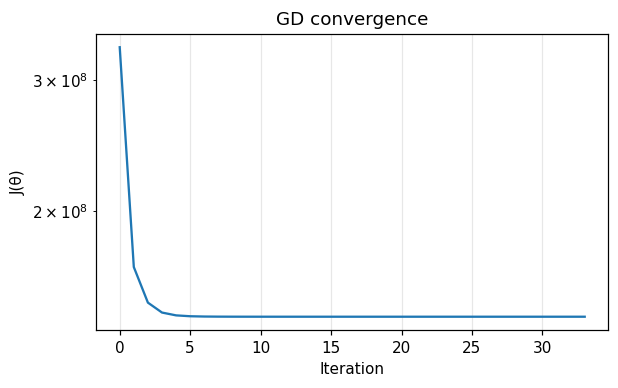

In [52]:
t0 = time.time()
theta_gd, hist_gd, lr_gd = gradient_descent(Xb_tr, ytr, lam=0.0)
print(f"GD: lr={lr_gd:.4f}, iterations={len(hist_gd)}, time={time.time() - t0:.2f}s, final loss={hist_gd[-1]:,.2f}")
record("Gradient descent (standardised X)", theta_gd, Xb_tr, Xb_te)
display(pd.DataFrame(res).T[["train_RMSE", "test_RMSE", "test_MAE", "test_R2", "test_MAPE%"]].round(3))
print("Max |theta_GD - theta_closed| =", f"{np.abs(theta_gd - theta_cf).max():.4e}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist_gd); ax.set_yscale("log"); ax.set_xlabel("Iteration"); ax.set_ylabel("J(θ)"); ax.set_title("GD convergence"); plt.show()

## Q3. Predicted vs. actual on the test data for Q1 and Q2  

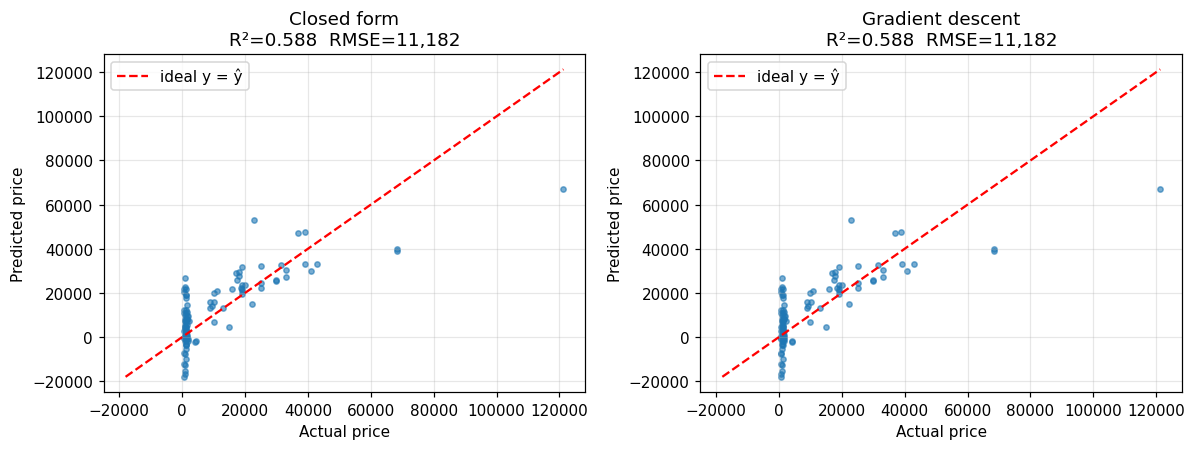

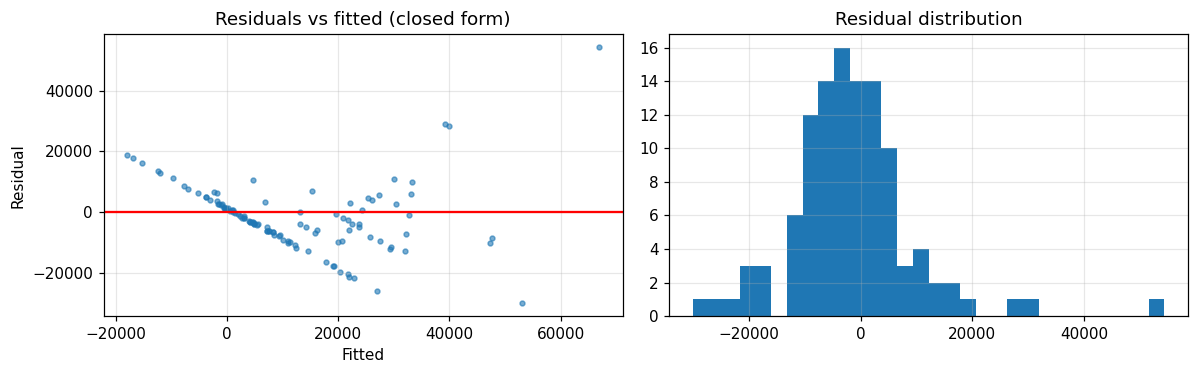

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
scatter_pred(ax[0], yte, Xb_te @ theta_cf, "Closed form")
scatter_pred(ax[1], yte, Xb_te @ theta_gd, "Gradient descent")
plt.tight_layout(); plt.show()

resid = yte - Xb_te @ theta_cf
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(Xb_te @ theta_cf, resid, s=10, alpha=.6); ax[0].axhline(0, color="r"); ax[0].set_title("Residuals vs fitted (closed form)")
ax[0].set_xlabel("Fitted"); ax[0].set_ylabel("Residual")
ax[1].hist(resid, bins=30); ax[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

**Error analysis.** Points on the red diagonal are perfect predictions. A curved/fanned residual pattern would indicate non-linearity or heteroscedasticity (e.g. premium brands priced non-linearly in RAM/storage), meaning a purely linear model leaves systematic error. Closed form and GD produce practically identical parameters, confirming that GD converges to the same global optimum of this convex objective; the closed form is exact but costs $O(d^3)$, GD scales better to large $d$ but needs scaling and a step size.

## Q4. Repeat Q1–Q3 with $\ell_2$ (Ridge) regularisation  

Best lambda (standardised) = 46.42 | Best lambda (raw) = 4.642


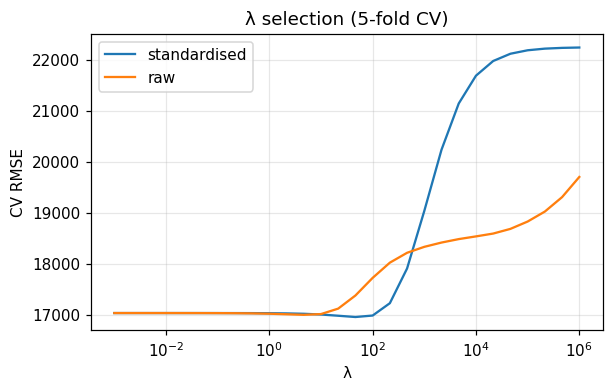

In [54]:
def cv_ridge(X, y, lams, k=5, seed=SEED):
    rng = np.random.default_rng(seed); idx = rng.permutation(len(X)); folds = np.array_split(idx, k)
    scores = []
    for lam in lams:
        errs = []
        for i in range(k):
            va = folds[i]; tr = np.hstack([folds[j] for j in range(k) if j != i])
            th = closed_form(add_bias(X[tr]), y[tr], lam)
            errs.append(rmse(y[va], add_bias(X[va]) @ th))
        scores.append(np.mean(errs))
    scores = np.array(scores)
    return lams[int(np.argmin(scores))], scores

lam_grid = np.logspace(-3, 6, 28)
best_lam_std, cv_std = cv_ridge(Xtr_s, ytr, lam_grid)
best_lam_raw, cv_raw = cv_ridge(Xtr, ytr, lam_grid)
print(f"Best lambda (standardised) = {best_lam_std:.4g} | Best lambda (raw) = {best_lam_raw:.4g}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(lam_grid, cv_std, label="standardised"); ax.semilogx(lam_grid, cv_raw, label="raw")
ax.set_xlabel("λ"); ax.set_ylabel("CV RMSE"); ax.set_title("λ selection (5-fold CV)"); ax.legend(); plt.show()

,train_RMSE,test_RMSE,test_MAE,test_R2,test_MAPE%
Closed form (raw X),16975.980,11182.357,7870.658,0.588,484.917
Closed form (standardised X),16975.980,11182.357,7870.658,0.588,484.917
Gradient descent (standardised X),16975.980,11182.356,7870.657,0.588,484.917
Ridge closed form (λ=46.4),17007.912,11051.818,7602.178,0.597,455.530
Ridge GD (λ=46.4),17007.912,11051.817,7602.177,0.597,455.530


Max |theta_ridge_GD - theta_ridge_closed| = 8.1863e-03


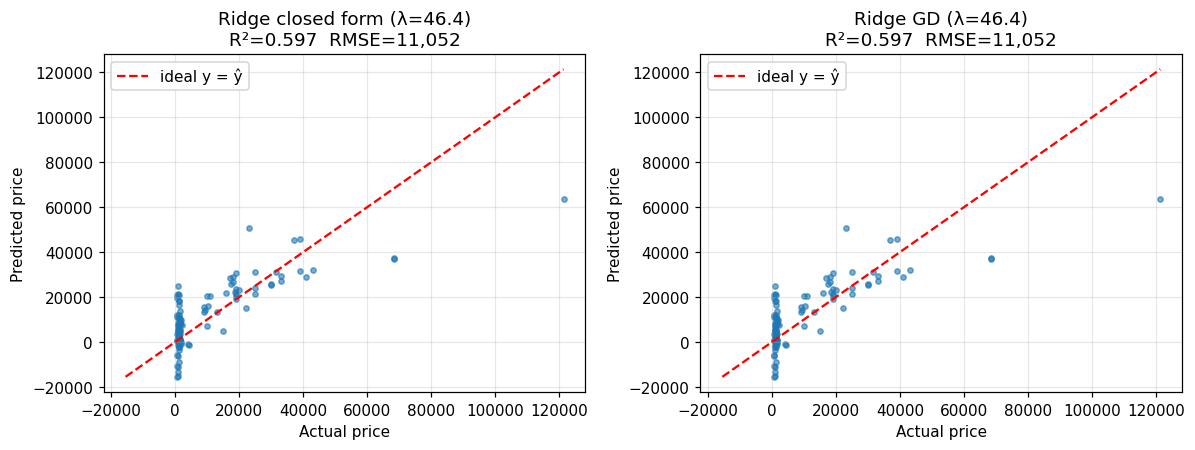

In [55]:
theta_r_cf = closed_form(Xb_tr, ytr, best_lam_std)
theta_r_gd, hist_r_gd, lr_r = gradient_descent(Xb_tr, ytr, lam=best_lam_std)
record(f"Ridge closed form (λ={best_lam_std:.3g})", theta_r_cf, Xb_tr, Xb_te)
record(f"Ridge GD (λ={best_lam_std:.3g})", theta_r_gd, Xb_tr, Xb_te)
display(pd.DataFrame(res).T[["train_RMSE", "test_RMSE", "test_MAE", "test_R2", "test_MAPE%"]].round(3))
print("Max |theta_ridge_GD - theta_ridge_closed| =", f"{np.abs(theta_r_gd - theta_r_cf).max():.4e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
scatter_pred(ax[0], yte, Xb_te @ theta_r_cf, f"Ridge closed form (λ={best_lam_std:.3g})")
scatter_pred(ax[1], yte, Xb_te @ theta_r_gd, f"Ridge GD (λ={best_lam_std:.3g})")
plt.tight_layout(); plt.show()

## Q5. Ridge with vs. without data standardisation  

In [56]:
rows = []
setups = {"With standardisation": (Xb_tr, Xb_te, best_lam_std), "Without standardisation": (Xb_tr_raw, Xb_te_raw, best_lam_raw)}
for setup, (A, B, lam) in setups.items():
    th = closed_form(A, ytr, lam)
    rows.append([setup, "Closed form", lam, rmse(ytr, A @ th), rmse(yte, B @ th), r2(yte, B @ th), mae(yte, B @ th), "-"])
    th2, h, lr_ = gradient_descent(A, ytr, lam=lam, n_iter=20000)
    rows.append([setup, "Gradient descent", lam, rmse(ytr, A @ th2), rmse(yte, B @ th2), r2(yte, B @ th2), mae(yte, B @ th2), len(h)])
cmp_df = pd.DataFrame(rows, columns=["Setting", "Method", "λ", "Train RMSE", "Test RMSE", "Test R²", "Test MAE", "GD iters"])
display(cmp_df.round(3))

,Setting,Method,λ,Train RMSE,Test RMSE,Test R²,Test MAE,GD iters
0,With standardisation,Closed form,46.416,17007.912,11051.818,0.597,7602.178,-
1,With standardisation,Gradient descent,46.416,17007.912,11051.817,0.597,7602.177,30
2,Without standardisation,Closed form,4.642,16991.237,11122.456,0.592,7768.628,-
3,Without standardisation,Gradient descent,4.642,19390.918,12771.372,0.462,8272.536,20000


**Comment.** Closed-form ridge may still fit well on raw data (the CV picks a $\lambda$ that suits the raw scale), but the penalty then shrinks features *unevenly*. Gradient descent on raw data is far slower (poor conditioning forces a tiny step size) and may stop before convergence, giving visibly worse test error.

## Q6. Predicted vs. actual for different $\lambda$ values  

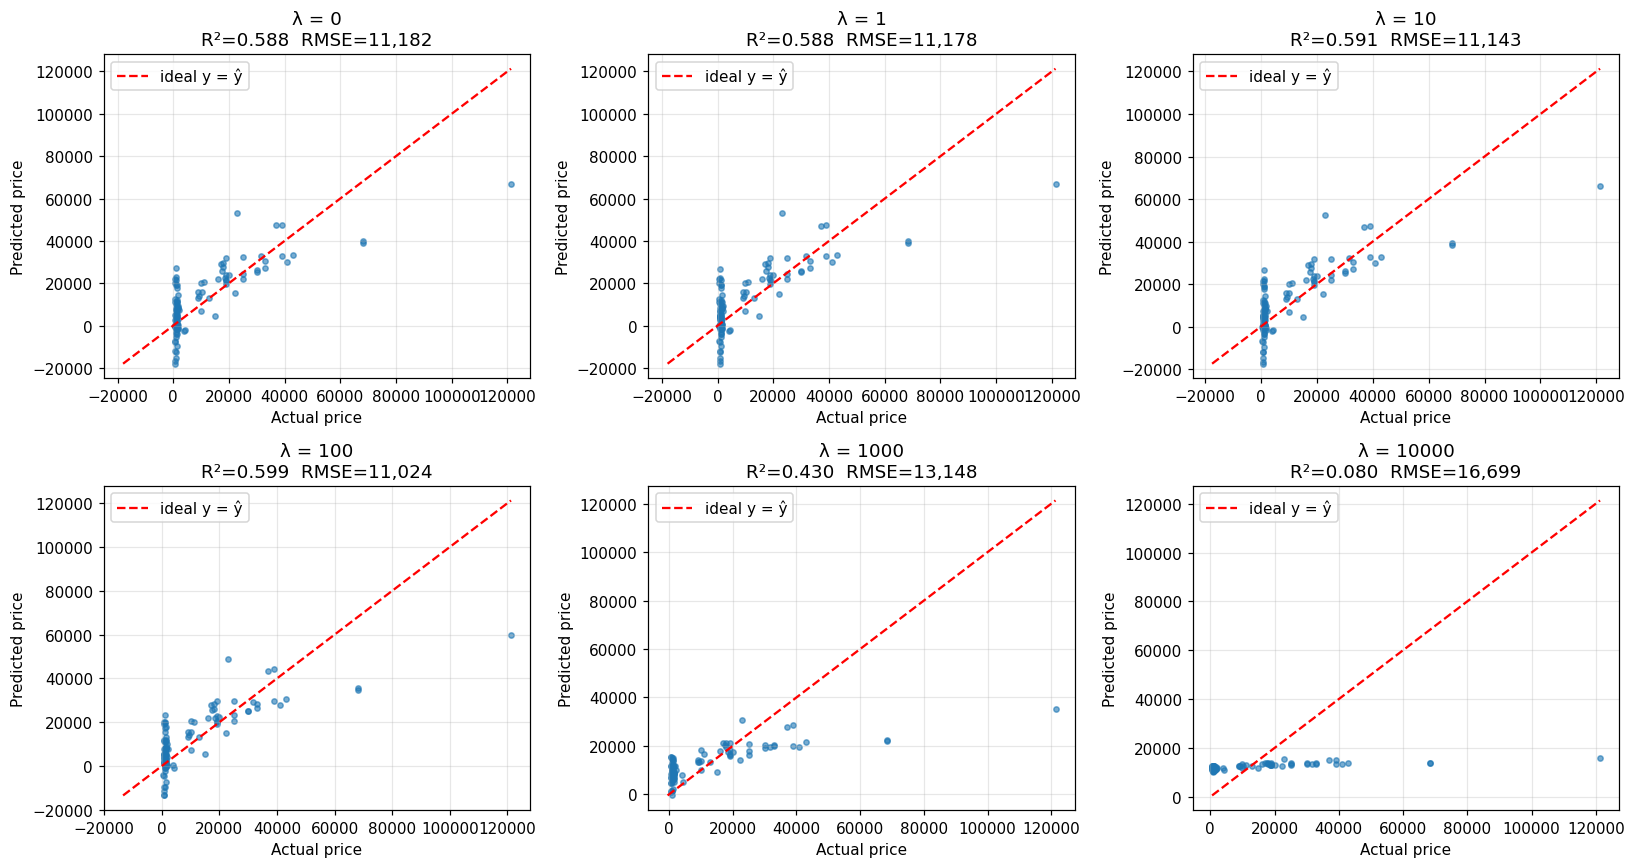

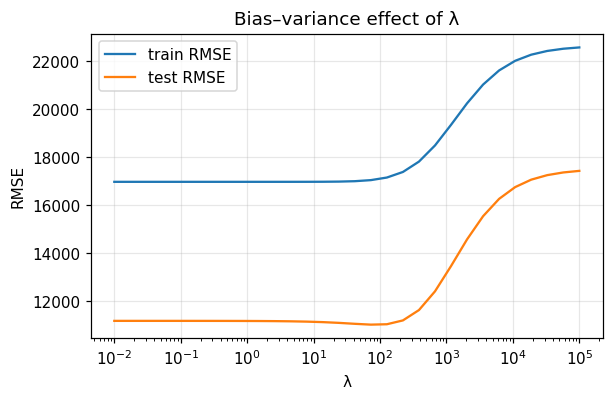

In [57]:
lam_list = [0, 1, 10, 100, 1000, 10000]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, lam in zip(axes.ravel(), lam_list):
    th = closed_form(Xb_tr, ytr, lam)
    scatter_pred(ax, yte, Xb_te @ th, f"λ = {lam}")
plt.tight_layout(); plt.show()

curve = []
for lam in np.logspace(-2, 5, 30):
    th = closed_form(Xb_tr, ytr, lam)
    curve.append([lam, rmse(ytr, Xb_tr @ th), rmse(yte, Xb_te @ th)])
curve = np.array(curve)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogx(curve[:, 0], curve[:, 1], label="train RMSE"); ax.semilogx(curve[:, 0], curve[:, 2], label="test RMSE")
ax.set_xlabel("λ"); ax.set_ylabel("RMSE"); ax.set_title("Bias–variance effect of λ"); ax.legend(); plt.show()

**Comment.** Small $\lambda$ ≈ ordinary least squares (lowest train error). Moderate $\lambda$ can slightly improve test error by shrinking noisy/correlated weights (variance ↓). Very large $\lambda$ shrinks all slopes to ≈0, so predictions collapse towards the mean price (horizontal band in the plot) → underfitting, high bias.

## Q7. Feature importance from the $\ell_2$ weights

,feature,weight,abs_weight
0,Ratings,7836.881,7836.881
2,ROM,4809.133,4809.133
4,Primary_Cam,-4784.836,4784.836
1,RAM,3484.100,3484.100
6,Battery_Power,2213.296,2213.296
5,Selfi_Cam,1100.502,1100.502
3,Mobile_Size,-60.626,60.626


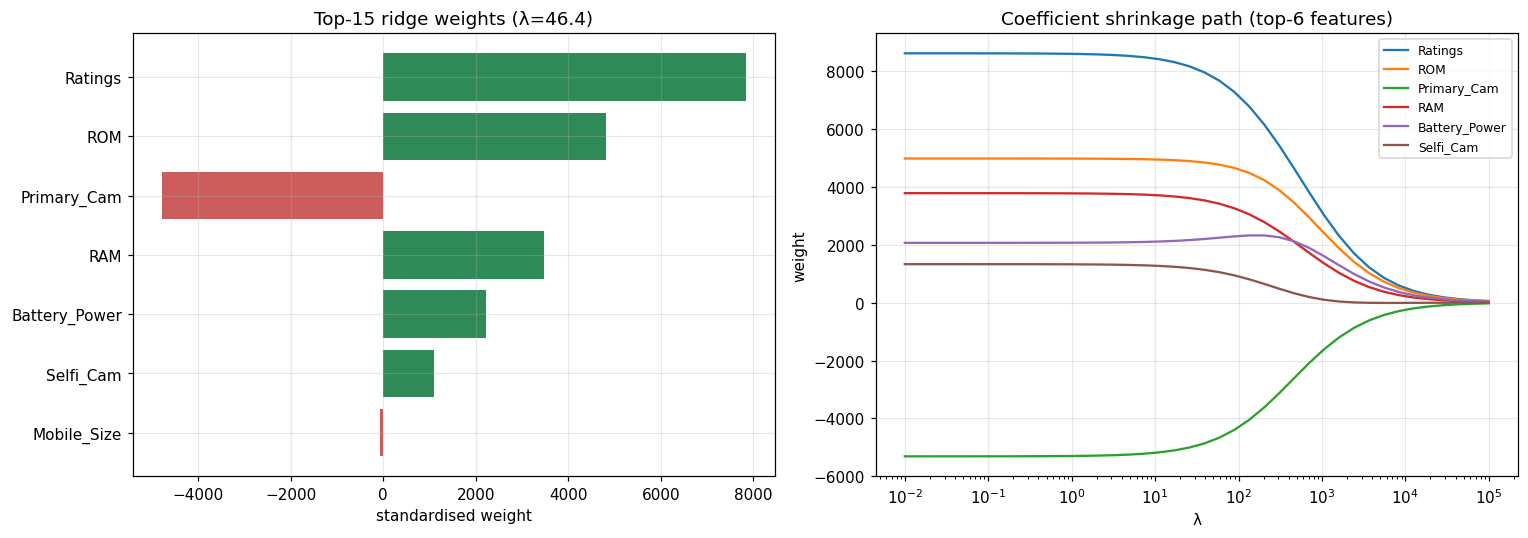

In [58]:
w = theta_r_cf[1:, 0]
imp = pd.DataFrame({"feature": feat_names, "weight": w, "abs_weight": np.abs(w)}).sort_values("abs_weight", ascending=False)
display(imp.head(15).round(3))

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(top.feature, top.weight, color=np.where(top.weight > 0, "seagreen", "indianred"))
ax[0].set_title(f"Top-15 ridge weights (λ={best_lam_std:.3g})"); ax[0].set_xlabel("standardised weight")

feat_idx = [feat_names.index(f) for f in imp.head(6).feature]
lams_path = np.logspace(-2, 5, 40)
paths = np.array([closed_form(Xb_tr, ytr, l)[1:, 0] for l in lams_path])
for j, f in zip(feat_idx, imp.head(6).feature):
    ax[1].semilogx(lams_path, paths[:, j], label=f)
ax[1].set_title("Coefficient shrinkage path (top-6 features)"); ax[1].set_xlabel("λ"); ax[1].set_ylabel("weight"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** Features with large $|w|$ drive the price (typically RAM, storage, brand dummies for premium brands, camera). Features whose weights shrink to ≈0 first as $\lambda$ grows carry little independent information or are collinear with others. Caveat: with correlated features, ridge spreads weight between them, so importance should be read as *association given the other features*, not causation.

**Overall suitability of the matrix-based linear model.** It is fast, convex, interpretable and (with standardisation + ridge) stable. Its limits are the linearity assumption (price often depends on interactions such as brand × RAM) and sensitivity to outliers; if residual plots show structure, add polynomial/interaction features or use non-linear models.

---
# Part 2 – Linear Classification: Bank Note Authentication



In [59]:
def make_synthetic_banknote(n=1372, seed=1):
    rng = np.random.default_rng(seed)
    n1 = int(n * 0.445); n0 = n - n1
    g = np.column_stack([rng.normal(2.3, 2.0, n0), rng.normal(4.0, 5.0, n0), rng.normal(0.8, 3.2, n0), rng.normal(-1.2, 2.1, n0)])
    f = np.column_stack([rng.normal(-1.9, 1.9, n1), rng.normal(-0.9, 5.0, n1), rng.normal(2.1, 5.3, n1), rng.normal(-1.2, 2.2, n1)])
    X = np.vstack([g, f]); y = np.r_[np.zeros(n0), np.ones(n1)]
    d = pd.DataFrame(X, columns=["variance", "skewness", "curtosis", "entropy"]); d["class"] = y.astype(int)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

if os.path.exists(BANKNOTE_FILE):
    bn = pd.read_csv(BANKNOTE_FILE)
    try:                                   # headerless UCI file: first "column name" parses as a float
        float(bn.columns[0]); bn = pd.read_csv(BANKNOTE_FILE, header=None)
        bn.columns = ["variance", "skewness", "curtosis", "entropy", "class"]
    except ValueError:
        pass
    USING_SYNTHETIC_BN = False
else:
    print(f"WARNING: '{BANKNOTE_FILE}' not found -> using SYNTHETIC stand-in data.")
    bn = make_synthetic_banknote(); USING_SYNTHETIC_BN = True

label_col = bn.columns[-1]
cls_feats = list(bn.columns[:-1])
print("Shape:", bn.shape, "| features:", cls_feats, "| missing:", int(bn.isna().sum().sum()))
display(bn.head()); display(bn[label_col].value_counts().rename("count").to_frame().T)

Shape: (1372, 5) | features: ['variance', 'skewness', 'curtosis', 'entropy'] | missing: 0


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


class,0,1
count,762,610


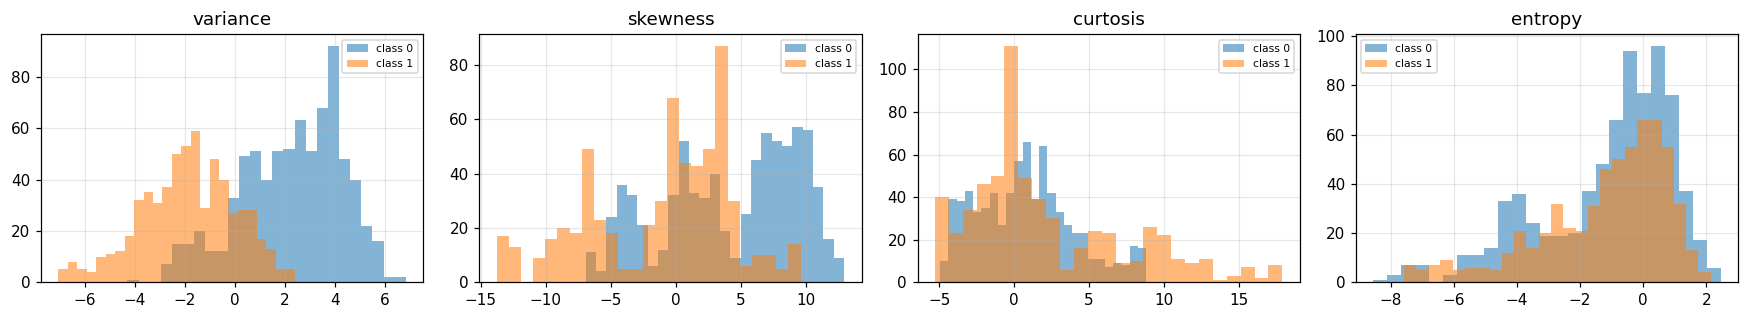

In [60]:
sns_like = bn.copy()
fig, ax = plt.subplots(1, len(cls_feats), figsize=(4 * len(cls_feats), 3))
for a, f in zip(ax, cls_feats):
    for c in sorted(bn[label_col].unique()):
        a.hist(bn.loc[bn[label_col] == c, f], bins=25, alpha=.55, label=f"class {c}")
    a.set_title(f); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Q1. Train/test split

In [61]:
Xc = bn[cls_feats].values.astype(float); yc = bn[label_col].values.astype(int)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=TEST_SIZE, random_state=SEED, stratify=yc)
print("Train:", Xc_tr.shape, "| class counts:", np.bincount(yc_tr))
print("Test :", Xc_te.shape, "| class counts:", np.bincount(yc_te))

def std_fit(X):
    m, s = X.mean(0), X.std(0); s[s == 0] = 1.0; return m, s

def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

class LogisticGD:
    def __init__(self, lam=0.0, lr=0.5, n_iter=4000):
        self.lam, self.lr, self.n_iter = lam, lr, n_iter
    def fit(self, X, y):
        n, d = X.shape; Xb = add_bias(X); y = y.reshape(-1, 1).astype(float)
        R = np.ones((d + 1, 1)); R[0] = 0
        lr_eff = min(self.lr, 1.0 / (self.lam / n + 1.0))   # keeps GD stable for large lambda
        self.theta = np.zeros((d + 1, 1)); self.hist = []
        for _ in range(self.n_iter):
            p = sigmoid(Xb @ self.theta)
            loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)) + self.lam * np.sum((R * self.theta) ** 2) / (2 * n)
            self.hist.append(loss)
            self.theta -= lr_eff * (Xb.T @ (p - y) + self.lam * R * self.theta) / n
        return self
    def predict_proba(self, X): return sigmoid(add_bias(X) @ self.theta).ravel()
    def predict(self, X): return (self.predict_proba(X) >= 0.5).astype(int)

def acc(y, yh): return float(np.mean(y == yh))

def train_eval(Xtr_, ytr_, Xte_, yte_, lam, lr=0.5, n_iter=4000):
    m_, s_ = std_fit(Xtr_)
    model = LogisticGD(lam, lr, n_iter).fit((Xtr_ - m_) / s_, ytr_)
    return model, m_, s_, acc(ytr_, model.predict((Xtr_ - m_) / s_)), acc(yte_, model.predict((Xte_ - m_) / s_))

mu_c, sd_c = std_fit(Xc_tr)
Xc_tr_s, Xc_te_s = (Xc_tr - mu_c) / sd_c, (Xc_te - mu_c) / sd_c

Train: (1097, 4) | class counts: [609 488]
Test : (275, 4) | class counts: [153 122]


## Q2. Fit with and without $\ell_2$ regularisation; compare accuracies

,λ,Train acc,Test acc,Test precision,Test recall,Test F1,||w||,final loss
0,0.0,0.9891,0.9818,0.9606,1.000,0.9799,12.9440,0.0284
1,0.1,0.9872,0.9782,0.9531,1.000,0.9760,11.9789,0.0370
2,1.0,0.9845,0.9709,0.9385,1.000,0.9683,8.0094,0.0765
3,10.0,0.9772,0.9709,0.9385,1.000,0.9683,4.0991,0.1928
4,100.0,0.9435,0.9382,0.9412,0.918,0.9295,1.5277,0.4186


Sanity check, λ=1  ->  ours: 0.9709 | sklearn (C=1): 0.9709


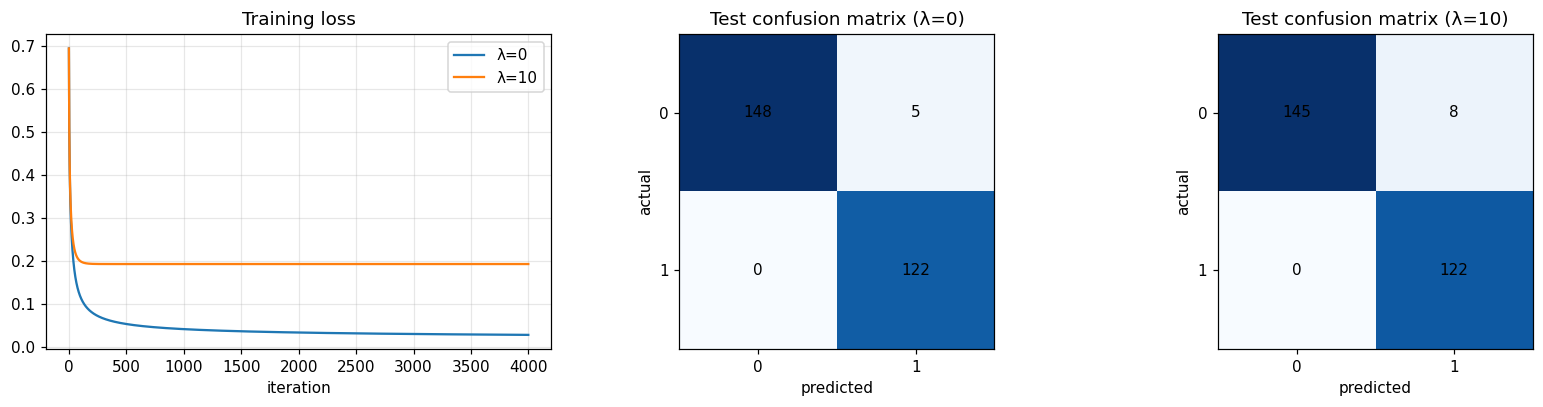

In [62]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression

rows, models = [], {}
for lam in [0, 0.1, 1, 10, 100]:
    m = LogisticGD(lam).fit(Xc_tr_s, yc_tr); models[lam] = m
    pt, pe = m.predict(Xc_tr_s), m.predict(Xc_te_s)
    rows.append([lam, acc(yc_tr, pt), acc(yc_te, pe), precision_score(yc_te, pe), recall_score(yc_te, pe), f1_score(yc_te, pe), np.linalg.norm(m.theta[1:]), m.hist[-1]])
clf_df = pd.DataFrame(rows, columns=["λ", "Train acc", "Test acc", "Test precision", "Test recall", "Test F1", "||w||", "final loss"])
display(clf_df.round(4))

# sanity check against scikit-learn (C = 1/λ under our loss scaling, which is sum-loss + λ/2||w||²)
sk = LogisticRegression(C=1.0, max_iter=5000).fit(Xc_tr_s, yc_tr)
print("Sanity check, λ=1  ->  ours:", round(acc(yc_te, models[1].predict(Xc_te_s)), 4), "| sklearn (C=1):", round(acc(yc_te, sk.predict(Xc_te_s)), 4))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(models[0].hist, label="λ=0"); ax[0].plot(models[10].hist, label="λ=10"); ax[0].set_title("Training loss"); ax[0].set_xlabel("iteration"); ax[0].legend()
for a, lam in zip(ax[1:], [0, 10]):
    cm = confusion_matrix(yc_te, models[lam].predict(Xc_te_s))
    a.imshow(cm, cmap="Blues"); a.set_title(f"Test confusion matrix (λ={lam})")
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xlabel("predicted"); a.set_ylabel("actual"); a.grid(False)
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", color="black")
plt.tight_layout(); plt.show()

## Q3. Training and test accuracy vs. $\lambda$

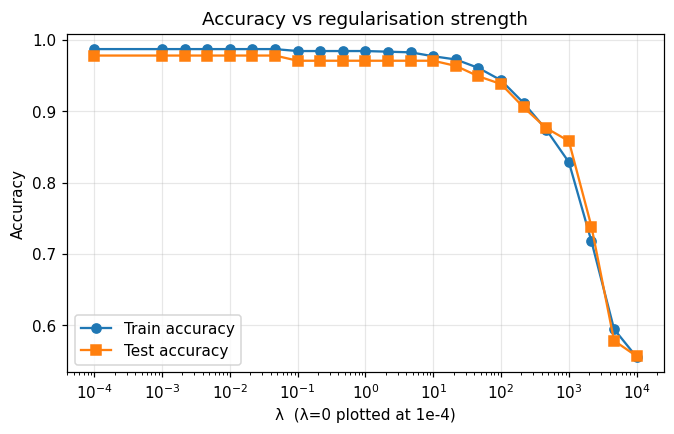

Best test accuracy 0.9782 at λ=0


In [63]:
lams_c = np.r_[0, np.logspace(-3, 4, 22)]
tr_acc, te_acc = [], []
for lam in lams_c:
    m = LogisticGD(lam, n_iter=3000).fit(Xc_tr_s, yc_tr)
    tr_acc.append(acc(yc_tr, m.predict(Xc_tr_s))); te_acc.append(acc(yc_te, m.predict(Xc_te_s)))
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.where(lams_c == 0, 1e-4, lams_c)          # plot λ=0 at 1e-4 on the log axis
ax.semilogx(xs, tr_acc, "o-", label="Train accuracy"); ax.semilogx(xs, te_acc, "s-", label="Test accuracy")
ax.set_xlabel("λ  (λ=0 plotted at 1e-4)"); ax.set_ylabel("Accuracy"); ax.set_title("Accuracy vs regularisation strength"); ax.legend(); plt.show()
best_idx = int(np.argmax(te_acc)); print(f"Best test accuracy {te_acc[best_idx]:.4f} at λ={lams_c[best_idx]:.4g}")

## Q4. 3-D visualisation using the three most important features  

,feature,weight,abs
1,skewness,-8.031,8.031
2,curtosis,-7.265,7.265
0,variance,-7.090,7.090
3,entropy,0.120,0.120


Top-3 features: ['skewness', 'curtosis', 'variance']
3-feature model: train acc=0.9891, test acc=0.9818


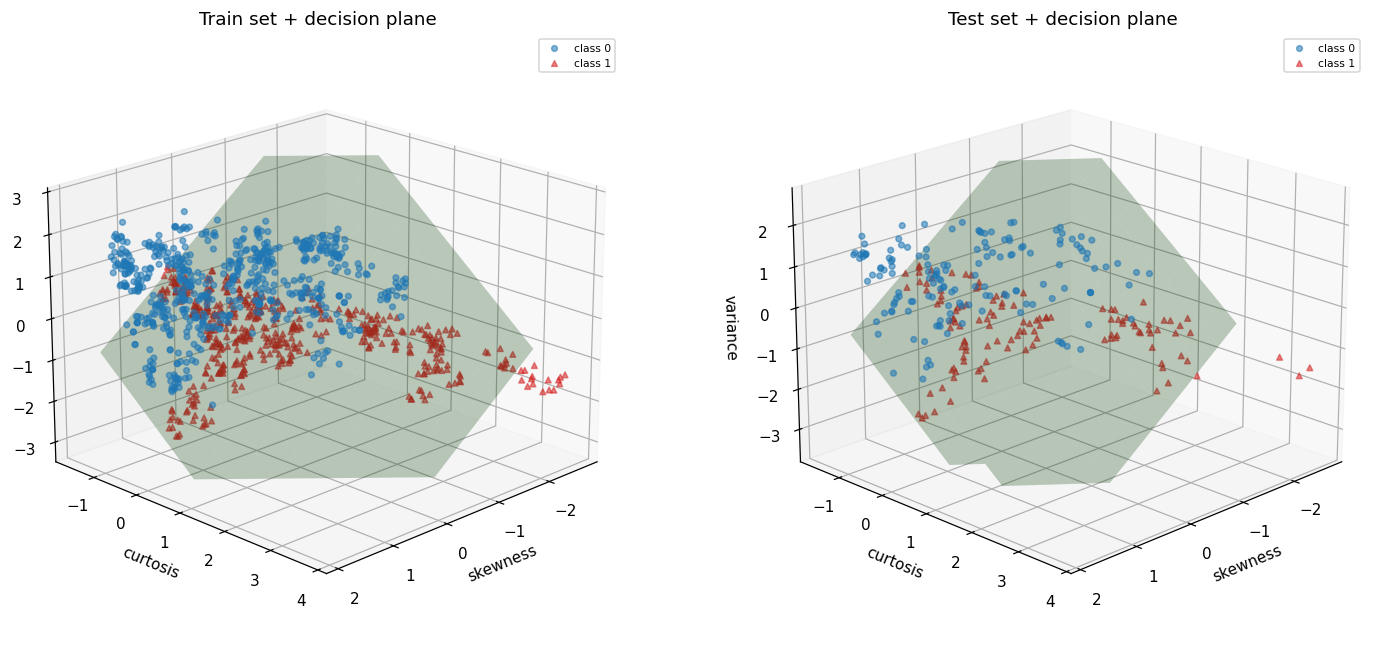

In [64]:
imp_c = pd.DataFrame({"feature": cls_feats, "weight": models[0].theta[1:, 0]})
imp_c["abs"] = imp_c.weight.abs(); imp_c = imp_c.sort_values("abs", ascending=False)
display(imp_c.round(3))
top3 = list(imp_c.feature.head(3)); top3_idx = [cls_feats.index(f) for f in top3]
print("Top-3 features:", top3)

def fit3(Xs3, y, lam=0.0):
    return LogisticGD(lam, n_iter=3000).fit(Xs3, y)

def plot3d(ax, X3, y, theta, title, outlier_mask=None, labels=top3):
    for c, col, mk in [(0, "tab:blue", "o"), (1, "tab:red", "^")]:
        sel = (y == c) if outlier_mask is None else ((y == c) & ~outlier_mask)
        ax.scatter(X3[sel, 0], X3[sel, 1], X3[sel, 2], c=col, marker=mk, s=14, alpha=.55, label=f"class {c}")
    if outlier_mask is not None and outlier_mask.any():
        ax.scatter(X3[outlier_mask, 0], X3[outlier_mask, 1], X3[outlier_mask, 2], c="black", marker="x", s=45, label="injected outliers")
    b, w1, w2, w3 = theta.ravel()
    if abs(w3) > 1e-8:
        lo, hi = np.percentile(X3, 1, axis=0), np.percentile(X3, 99, axis=0)
        gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 12), np.linspace(lo[1], hi[1], 12))
        gz = -(b + w1 * gx + w2 * gy) / w3
        gz = np.where((gz >= lo[2] - 1) & (gz <= hi[2] + 1), gz, np.nan)
        ax.plot_surface(gx, gy, gz, alpha=.25, color="green")
    ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1]); ax.set_zlabel(labels[2]); ax.set_title(title); ax.legend(fontsize=7)

X3_tr = Xc_tr_s[:, top3_idx]; X3_te = Xc_te_s[:, top3_idx]
m3 = fit3(X3_tr, yc_tr)
print(f"3-feature model: train acc={acc(yc_tr, m3.predict(X3_tr)):.4f}, test acc={acc(yc_te, m3.predict(X3_te)):.4f}")
fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(121, projection="3d"); plot3d(ax1, X3_tr, yc_tr, m3.theta, "Train set + decision plane")
ax2 = fig.add_subplot(122, projection="3d"); plot3d(ax2, X3_te, yc_te, m3.theta, "Test set + decision plane")
for a in (ax1, ax2): a.view_init(elev=20, azim=45)
plt.tight_layout(); plt.show()

## Q5. Intentionally inject outliers by shifting data points  


Shifted 55 of 1097 training points (5.0%).


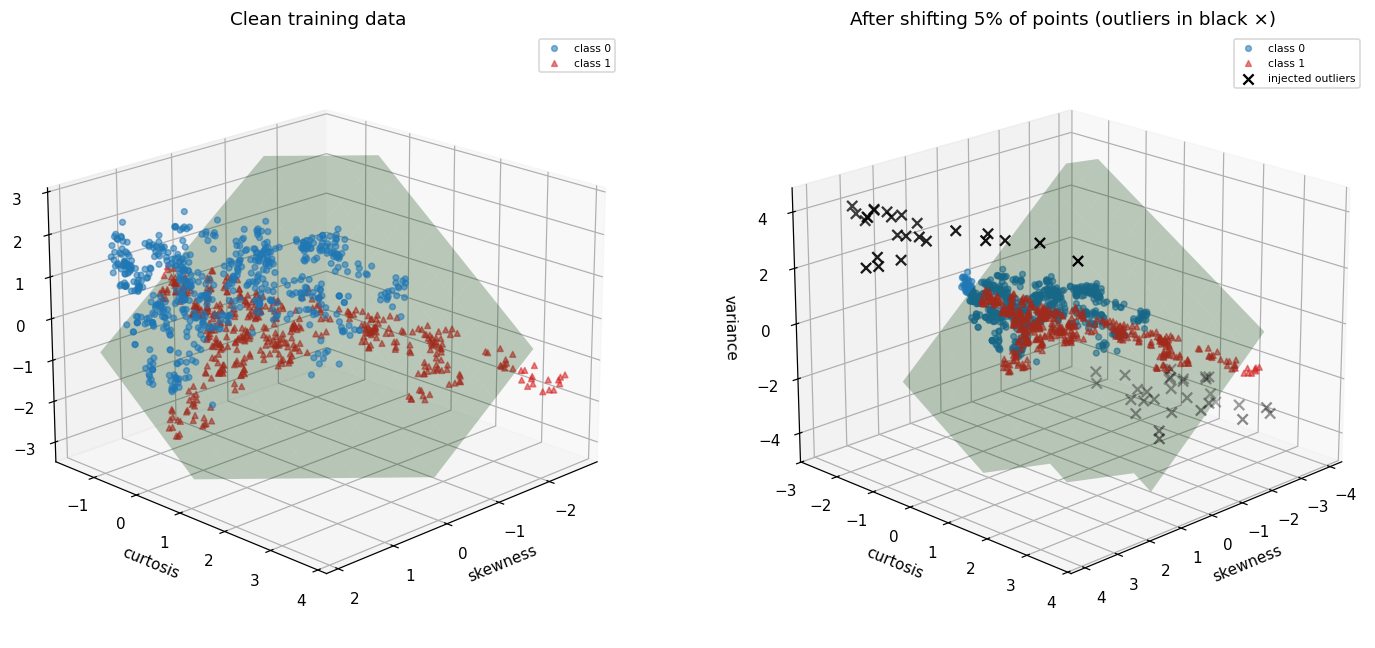

In [65]:
def inject_outliers(X, y, frac=0.05, magnitude=4.0, mode="random", seed=0):
    rng = np.random.default_rng(seed)
    Xo = X.copy(); n = len(X)
    idx = rng.choice(n, int(round(frac * n)), replace=False)
    mask = np.zeros(n, dtype=bool); mask[idx] = True
    sigma = X.std(0)
    if mode == "random":
        Xo[idx] += magnitude * sigma * rng.choice([-1, 1], size=(len(idx), X.shape[1]))
    else:
        mus = {c: X[y == c].mean(0) for c in np.unique(y)}
        for i in idx:
            other = 1 - y[i]
            Xo[i] += magnitude * (mus[other] - mus[y[i]])
    return Xo, mask

Xo_tr, omask = inject_outliers(Xc_tr, yc_tr, frac=0.05, magnitude=4.0, mode="toward_other")
print(f"Shifted {omask.sum()} of {len(omask)} training points ({omask.mean():.1%}).")

# scatter on the standardised top-3 feature space (scaler re-fitted on the contaminated training data, as in practice)
mo, so = std_fit(Xo_tr)
Xo_tr_s = (Xo_tr - mo) / so
fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(121, projection="3d"); plot3d(ax1, Xc_tr_s[:, top3_idx], yc_tr, m3.theta, "Clean training data")
ax2 = fig.add_subplot(122, projection="3d"); plot3d(ax2, Xo_tr_s[:, top3_idx], yc_tr, m3.theta, "After shifting 5% of points (outliers in black ×)", outlier_mask=omask)
for a in (ax1, ax2): a.view_init(elev=20, azim=45)
plt.tight_layout(); plt.show()

## Q6. Fit the classifier on outlier-injected data and comment on its impact

,λ,Test acc (clean train),Train acc (outlier),Test acc (outlier train),Accuracy drop,||w|| clean,||w|| outlier
0,0,0.9818,0.9325,0.9745,0.0073,12.9440,1.1338
1,1,0.9709,0.9353,0.9782,-0.0073,8.0094,1.1116
2,10,0.9709,0.9316,0.9927,-0.0218,4.0991,0.9574
3,100,0.9382,0.7967,0.8727,0.0655,1.5277,0.4943


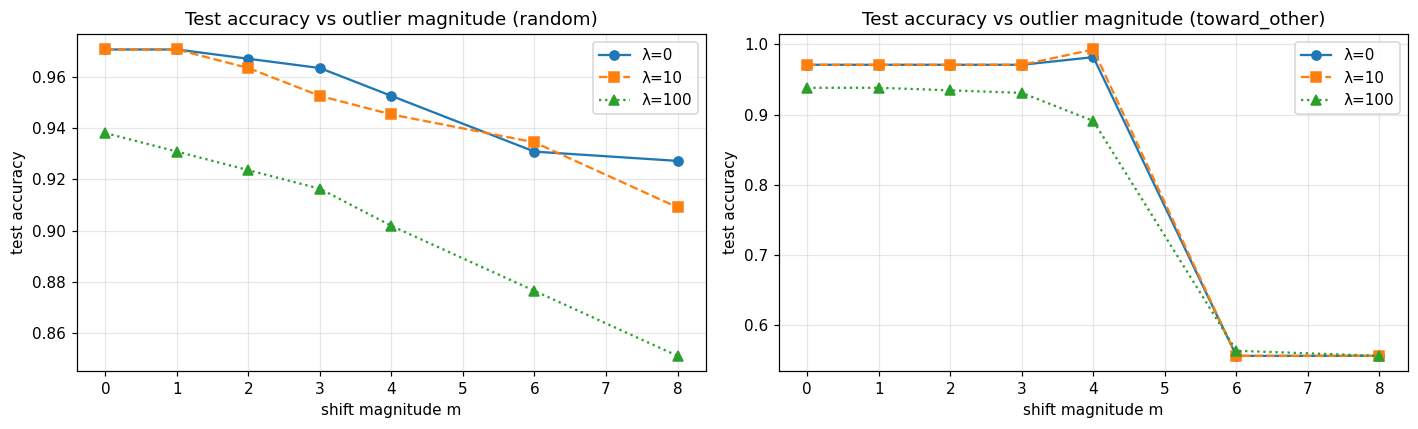

3-feature plane parameters  clean: [-2.551 -7.576 -6.776 -6.573] | contaminated: [-0.239 -0.664 -0.565 -0.717]


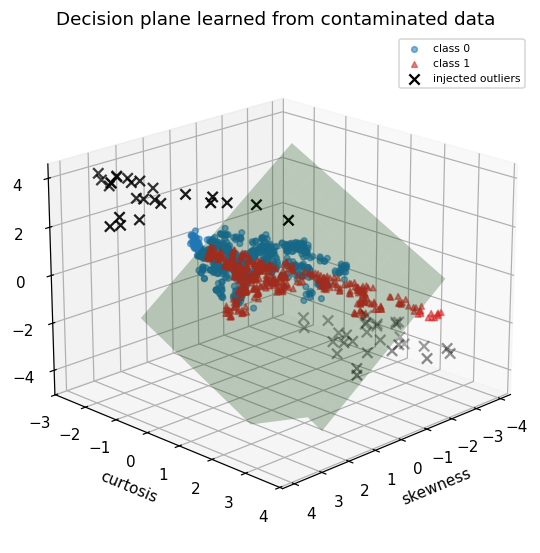

In [66]:
rows = []
for lam in [0, 1, 10, 100]:
    mc, _, _, a_tr_c, a_te_c = train_eval(Xc_tr, yc_tr, Xc_te, yc_te, lam)            # clean training data
    mo_, m_, s_, a_tr_o, a_te_o = train_eval(Xo_tr, yc_tr, Xc_te, yc_te, lam)         # contaminated training data
    rows.append([lam, a_te_c, a_tr_o, a_te_o, a_te_c - a_te_o, np.linalg.norm(mc.theta[1:]), np.linalg.norm(mo_.theta[1:])])
out_df = pd.DataFrame(rows, columns=["λ", "Test acc (clean train)", "Train acc (outlier)", "Test acc (outlier train)", "Accuracy drop", "||w|| clean", "||w|| outlier"])
display(out_df.round(4))

# Sweep over the shift magnitude for both contamination modes
mags = [0, 1, 2, 3, 4, 6, 8]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, mode in zip(ax, ["random", "toward_other"]):
    for lam, ls in [(0, "o-"), (10, "s--"), (100, "^:")]:
        accs = []
        for mg in mags:
            Xo_, _ = inject_outliers(Xc_tr, yc_tr, 0.05, mg, mode, seed=1)
            accs.append(train_eval(Xo_, yc_tr, Xc_te, yc_te, lam, n_iter=2000)[4])
        a.plot(mags, accs, ls, label=f"λ={lam}")
    a.set_title(f"Test accuracy vs outlier magnitude ({mode})"); a.set_xlabel("shift magnitude m"); a.set_ylabel("test accuracy"); a.legend()
plt.tight_layout(); plt.show()

# decision plane before vs after contamination (3 features)
mo3 = fit3(Xo_tr_s[:, top3_idx], yc_tr)
print("3-feature plane parameters  clean:", np.round(m3.theta.ravel(), 3), "| contaminated:", np.round(mo3.theta.ravel(), 3))
fig = plt.figure(figsize=(7, 6)); ax = fig.add_subplot(111, projection="3d")
plot3d(ax, Xo_tr_s[:, top3_idx], yc_tr, mo3.theta, "Decision plane learned from contaminated data", outlier_mask=omask); ax.view_init(20, 45); plt.show()